<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS09/datasetPBL/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

# Load dan gabungkan dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df_merged = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ambil 2 fitur numerik non-negatif (rating_cafe dan review_count)
# Ubah ke bentuk diskrit bulat positif (seperti pada modul agar bisa diproses MultinomialNB)
fitur_1 = np.round(np.absolute(df_merged['rating_cafe'].fillna(0).values), 2) * 100
fitur_2 = np.absolute(df_merged['review_count'].fillna(0).values)

X = np.column_stack((fitur_1, fitur_2)).astype(int)

# Target biner: 1 jika rating_review == 5 (Kelas A), 0 jika rating_review < 5 (Kelas B)
y = (df_merged['rating_review'].fillna(0).values >= 5).astype(int)

# Cek Hasil
print("Shape X:", X.shape)
print("Contoh X (5 baris pertama):\n", X[:5])
print("Contoh y (10 data pertama):", y[:10])

Shape X: (2230, 2)
Contoh X (5 baris pertama):
 [[470 528]
 [470 528]
 [470 528]
 [470 528]
 [470 528]]
Contoh y (10 data pertama): [1 1 1 1 1 1 1 0 1 1]


In [2]:
# Reshape label y menjadi 2D
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,470,528,1
1,470,528,1
2,470,528,1
3,470,528,1
4,470,528,1


In [3]:
# Definisikan nama label
labels = {
    1: 'Kelas A',   # Rating Review Tinggi (5)
    0: 'Kelas B'    # Rating Review Sedang/Rendah (< 5)
}

# Copy Data Frame untuk menyimpan Data Frame baru dengan label yang mudah dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,470,528,Kelas A
1,470,528,Kelas A
2,470,528,Kelas A
3,470,528,Kelas A
4,470,528,Kelas A


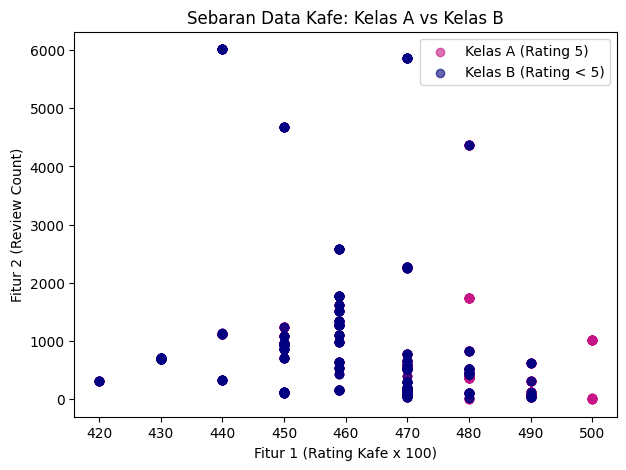

In [4]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group(('Kelas A',))
class_b = gb.get_group(('Kelas B',))

# Plot
plt.figure(figsize=(7, 5))
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'], alpha=0.6)
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'], alpha=0.6)
plt.xlabel('Fitur 1 (Rating Kafe x 100)')
plt.ylabel('Fitur 2 (Review Count)')
plt.title('Sebaran Data Kafe: Kelas A vs Kelas B')
plt.legend(['Kelas A (Rating 5)', 'Kelas B (Rating < 5)'])
plt.show()

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Split data training dan testing (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training & evaluasi akurasi
y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data & evaluasi akurasi
y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Multinomial): {acc_train:.4f}')
print(f'Hasil akurasi data test (Multinomial) : {acc_test:.4f}')

Hasil akurasi data train (Multinomial): 0.6553
Hasil akurasi data test (Multinomial) : 0.6442


In [6]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi obyek GaussianNB
gnb = GaussianNB()

# Fit model menggunakan split data training & testing yang sama
gnb.fit(X_train, y_train)

# Prediksi dengan data training & evaluasi akurasi
y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data & evaluasi akurasi
y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb:.4f}')
print(f'Hasil akurasi data test (Gaussian) : {acc_test_gnb:.4f}')

Hasil akurasi data train (Gaussian): 0.7905
Hasil akurasi data test (Gaussian) : 0.7892
